# Tarea 1 · Parte 2 – Del LLM al clasificador

**Pregunta guía:** ¿podemos convertir titulares peruanos en un clasificador de noticias?

En este notebook comparamos tres formas de clasificar un titular en `politica`, `economia`,
`deportes` o `ciencia_tecnologia`:

1. **Zero-shot:** un modelo que nunca vio nuestros datos (el piso a superar).
2. **LLM (Gemini):** etiqueta todo el dataset; es la *supervisión débil*.
3. **Transformer con fine-tuning:** DistilBERT multilingüe entrenado con las etiquetas del LLM.

La etiqueta "verdadera" con la que evaluamos es la sección del diario (`etiqueta` en
`datos/noticias.csv`). Todo se mide en el **conjunto de test**, que no se toca hasta el final.

In [1]:
import json
import os
import time
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
pd.set_option("display.max_colwidth", 90)

In [2]:
noticias = pd.read_csv("datos/noticias.csv", dtype=str)
print(noticias.shape)
noticias["etiqueta"].value_counts()

(383, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    95
politica              91
Name: count, dtype: int64

## 1. Partición 70 / 15 / 15

La hacemos **primero**, antes de cualquier modelo, para que el test quede aislado desde el
inicio. Es estratificada (cada parte conserva la proporción de categorías) y con
`random_state=42` para que siempre salga igual.

In [3]:
entrenamiento, resto = train_test_split(
    noticias, test_size=0.30, stratify=noticias["etiqueta"], random_state=SEMILLA
)
validacion, test = train_test_split(
    resto, test_size=0.50, stratify=resto["etiqueta"], random_state=SEMILLA
)

tamanos = pd.DataFrame({
    "conjunto": ["train", "validación", "test"],
    "noticias": [len(entrenamiento), len(validacion), len(test)],
})
tamanos["porcentaje"] = (tamanos["noticias"] / len(noticias) * 100).round(1)
tamanos

,conjunto,noticias,porcentaje
0,train,268,70.0
1,validación,57,14.9
2,test,58,15.1


In [4]:
pd.crosstab(
    pd.concat([entrenamiento.assign(conjunto="train"), validacion.assign(conjunto="val"), test.assign(conjunto="test")])["etiqueta"],
    pd.concat([entrenamiento.assign(conjunto="train"), validacion.assign(conjunto="val"), test.assign(conjunto="test")])["conjunto"],
)

conjunto,test,train,val
etiqueta,,,
ciencia_tecnologia,15,66,14
deportes,15,69,14
economia,15,69,15
politica,13,64,14


## 2. Línea base zero-shot (sin entrenamiento)

`Recognai/bert-base-spanish-wwm-cased-xnli` es un BERT en español entrenado para decidir si
una frase "implica" otra. Le preguntamos, para cada titular, si implica "Esta noticia trata
sobre política", "...sobre economía", etc., y nos quedamos con la opción más probable.

Usamos 40 titulares del test (10 por categoría), como pide el enunciado.

In [5]:
from transformers import pipeline

clasificador_zero_shot = pipeline(
    "zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli"
)

# el modelo entiende mejor palabras normales que nuestras etiquetas con guion bajo
etiqueta_en_palabras = {
    "política": "politica",
    "economía": "economia",
    "deportes": "deportes",
    "ciencia y tecnología": "ciencia_tecnologia",
}

C:\Users\User\Documents\GitHub\Noticias-peruanas\tarea_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device set to use cpu


In [6]:
def predecir_zero_shot(titulares):
    resultados = clasificador_zero_shot(
        list(titulares),
        candidate_labels=list(etiqueta_en_palabras.keys()),
        hypothesis_template="Esta noticia trata sobre {}.",
    )
    return [etiqueta_en_palabras[resultado["labels"][0]] for resultado in resultados]


muestra_40 = test.groupby("etiqueta").sample(n=10, random_state=SEMILLA)

inicio = time.time()
muestra_40 = muestra_40.assign(prediccion_zero_shot=predecir_zero_shot(muestra_40["titular"]))
segundos_zero_shot_40 = time.time() - inicio

accuracy_zero_shot_40 = accuracy_score(muestra_40["etiqueta"], muestra_40["prediccion_zero_shot"])
f1_zero_shot_40 = f1_score(muestra_40["etiqueta"], muestra_40["prediccion_zero_shot"], average="macro")
print(f"Zero-shot en 40 titulares → accuracy: {accuracy_zero_shot_40:.3f} | F1 macro: {f1_zero_shot_40:.3f}")
print(f"Tiempo: {segundos_zero_shot_40:.1f} s")

Zero-shot en 40 titulares → accuracy: 0.625 | F1 macro: 0.591
Tiempo: 31.1 s


In [7]:
muestra_40[["titular", "etiqueta", "prediccion_zero_shot"]].head(10)

,titular,etiqueta,prediccion_zero_shot
340,"Francis Halzen, el nuevo premio nobel de Física, cuenta que usa la IA desde los 90: “E...",ciencia_tecnologia,deportes
320,HomeView: Apple entra de lleno en el hogar con su primera pantalla inteligente con IA,ciencia_tecnologia,economia
375,El Nobel de Física atribuye su galardón al talento de sus colaboradores y la suerte,ciencia_tecnologia,deportes
363,Un Motorola razr 70 diferente: así es el teléfono de lujo con 34 cristales Swarovski S...,ciencia_tecnologia,deportes
311,YouTube planea incorporar audiolibros en 2027 y ya estaría en conversación con editori...,ciencia_tecnologia,economia
348,"Apple anuncia evento para el 13 de octubre: presentaría su nuevo HomePad, Apple TV y H...",ciencia_tecnologia,economia
329,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de l...,ciencia_tecnologia,ciencia_tecnologia
381,"Quién es Francis Halzen, el Nobel que dedica su vida al observatorio de neutrinos a es...",ciencia_tecnologia,ciencia_tecnologia
290,Videojuego peruano “Dark Rally” abre concurso para convertirte en uno de sus personajes,ciencia_tecnologia,deportes
351,Por qué China considera una amenaza la IA que imita las relaciones humanas,ciencia_tecnologia,politica


## 3. Supervisión débil con un LLM (Gemini)

Le mandamos los titulares a Gemini en lotes de 50 (el plan gratuito permite solo 20 solicitudes al día por modelo) con un prompt estructurado y le pedimos que
responda **solo** con JSON: una categoría y una confianza entre 0 y 1 por titular. La clave
de la API se lee de `.env` (no está en el notebook ni en GitHub).

Igual que con el scraping, si `datos/etiquetas_llm.csv` ya existe no volvemos a llamar a la
API: cada llamada cuesta cuota y no queremos resultados distintos cada vez que se corre.

In [8]:
MODELO_LLM = "gemini-3.5-flash-lite"
TAMANO_LOTE = 50

PROMPT = '''Eres un editor de un diario peruano. Clasifica cada titular en UNA de estas
4 categorías, escritas exactamente así:

- politica: Congreso, Gobierno, elecciones, partidos, justicia y política internacional.
- economia: mercados, dólar, empresas, empleo, impuestos, finanzas y economía del Perú y el mundo.
- deportes: fútbol, vóley, atletismo y cualquier otra competencia deportiva.
- ciencia_tecnologia: ciencia, salud científica, espacio, ecología, tecnología, internet,
  inteligencia artificial, celulares y videojuegos.

Para cada titular devuelve su número, la categoría y tu confianza entre 0 y 1.

Titulares:
{titulares}'''

In [9]:
from google import genai
from google.genai import errors
from google.genai import types
from pydantic import BaseModel


class Clasificacion(BaseModel):
    numero: int
    categoria: str
    confianza: float


def etiquetar_lote(cliente, titulares):
    lista = "\n".join(f"{numero}. {titular}" for numero, titular in enumerate(titulares, start=1))
    configuracion = types.GenerateContentConfig(
        response_mime_type="application/json",
        response_schema=list[Clasificacion],
        temperature=0,
    )
    # en horas punta Gemini responde "503: alta demanda"; esperamos y probamos de nuevo
    for intento in [1, 2, 3]:
        try:
            respuesta = cliente.models.generate_content(
                model=MODELO_LLM, contents=PROMPT.format(titulares=lista), config=configuracion
            )
            return respuesta.parsed
        except errors.ServerError as error:
            print(f"  intento {intento}: {error.code}, esperamos 15 s")
            time.sleep(15)
    raise RuntimeError("Gemini no respondió después de 3 intentos")

In [10]:
archivo_llm = "datos/etiquetas_llm.csv"
archivo_tiempo_llm = "modelo/tiempo_llm.json"

if os.path.exists(archivo_llm):
    etiquetas_llm = pd.read_csv(archivo_llm)
    with open(archivo_tiempo_llm, encoding="utf-8") as archivo:
        segundos_api_llm = json.load(archivo)["segundos_api"]
    print(f"Usando etiquetas guardadas: {len(etiquetas_llm)} titulares")
else:
    load_dotenv(".env")
    cliente = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
    titulares = noticias["titular"].tolist()
    filas = []
    segundos_api_llm = 0
    for posicion in range(0, len(titulares), TAMANO_LOTE):
        lote = titulares[posicion:posicion + TAMANO_LOTE]
        inicio = time.time()
        respuesta_lote = etiquetar_lote(cliente, lote)
        segundos_api_llm += time.time() - inicio
        for clasificacion in respuesta_lote:
            filas.append({
                "titular": lote[clasificacion.numero - 1],
                "etiqueta_llm": clasificacion.categoria,
                "confianza": clasificacion.confianza,
            })
        print(f"{min(posicion + TAMANO_LOTE, len(titulares))} de {len(titulares)} titulares")
        time.sleep(4)  # respeta el límite de solicitudes por minuto del plan gratuito
    print(f"Tiempo esperando a la API: {segundos_api_llm:.0f} s")
    etiquetas_llm = pd.DataFrame(filas)
    etiquetas_llm["modelo_llm"] = MODELO_LLM
    etiquetas_llm["fecha"] = date.today().isoformat()
    etiquetas_llm.to_csv(archivo_llm, index=False, encoding="utf-8")
    with open(archivo_tiempo_llm, "w", encoding="utf-8") as archivo:
        json.dump({"segundos_api": segundos_api_llm, "titulares": len(titulares)}, archivo)

etiquetas_llm.head()

Usando etiquetas guardadas: 383 titulares


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ...,economia,0.95,gemini-3.5-flash-lite,2026-10-18
1,César Acuña anuncia su retiro de la política: ¿qué factores impulsarían su decisión?,politica,1.00,gemini-3.5-flash-lite,2026-10-18
2,De Gregorio Santos a “El lunarejo”: más de 8 mil condenados solicitaron el indulto pre...,politica,0.90,gemini-3.5-flash-lite,2026-10-18
3,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facul...,politica,1.00,gemini-3.5-flash-lite,2026-10-18
4,"Alfonso, ¿ahora qué?, una crónica de Fernando Vivas sobre López-Chau, líder de Ahora N...",politica,0.95,gemini-3.5-flash-lite,2026-10-18


In [11]:
print("Titulares etiquetados:", len(etiquetas_llm), "de", len(noticias))
print("Etiquetas fuera de las 4 categorías:", (~etiquetas_llm["etiqueta_llm"].isin(CATEGORIAS)).sum())
etiquetas_llm["etiqueta_llm"].value_counts()

Titulares etiquetados: 383 de 383
Etiquetas fuera de las 4 categorías: 0


etiqueta_llm
politica              98
deportes              98
economia              94
ciencia_tecnologia    93
Name: count, dtype: int64

In [12]:
# pegamos la etiqueta del LLM a cada noticia; un titular repetido se queda con una sola fila
etiquetas_unicas = etiquetas_llm.drop_duplicates(subset="titular")[["titular", "etiqueta_llm", "confianza"]]
entrenamiento = entrenamiento.merge(etiquetas_unicas, on="titular", how="left")
validacion = validacion.merge(etiquetas_unicas, on="titular", how="left")
test = test.merge(etiquetas_unicas, on="titular", how="left")

coincide = (pd.concat([entrenamiento, validacion])["etiqueta_llm"] == pd.concat([entrenamiento, validacion])["etiqueta"]).mean()
print(f"En train + validación, el LLM coincide con la sección del diario en el {coincide:.1%} de los casos")

En train + validación, el LLM coincide con la sección del diario en el 92.0% de los casos


### 3.1 Auditoría humana de 20 predicciones

Tomamos 20 titulares al azar y una persona (la autora de este trabajo) revisa uno por uno si
la etiqueta del LLM es correcta. La revisión está en `datos/auditoria_humana.csv`: la
columna `acuerdo_humano` vale `1` si la persona está de acuerdo con el LLM y `0` si no.

In [13]:
archivo_auditoria = "datos/auditoria_humana.csv"

if not os.path.exists(archivo_auditoria):
    muestra_auditoria = etiquetas_llm.sample(n=20, random_state=SEMILLA)[["titular", "etiqueta_llm", "confianza"]]
    muestra_auditoria["acuerdo_humano"] = ""
    muestra_auditoria["comentario"] = ""
    muestra_auditoria.to_csv(archivo_auditoria, index=False, encoding="utf-8")
    print("Se creó el archivo de auditoría: falta llenarlo a mano")

auditoria = pd.read_csv(archivo_auditoria)
auditoria

,titular,bajada,etiqueta_llm,confianza,acuerdo_humano,comentario,url
0,"Mourinho sorprende con mensaje sobre Vinícius: “Si estuviese en su lugar, probablement...",José Mourinho defendió a Vinícius y destacó su fortaleza para afrontar las críticas en...,deportes,1.00,1,NaN,https://elcomercio.pe/deporte-total/futbol-mundial/mourinho-sorprende-con-mensaje-sobr...
1,A una etapa del objetivo: Annia Cillóniz completó el tramo entre Cusco y Puno y mantie...,Annia Cillóniz llegó a Puno y a falta de la última etapa mantiene su ventaja en la cat...,deportes,1.00,1,NaN,https://elcomercio.pe/deporte-total/caminos-del-inca-2026-a-una-etapa-del-objetivo-ann...
2,"Google lanza Gemini 4 Argon, su nuevo modelo de frontera que supera a GPT-6 Astra y Cl...",El nuevo modelo superaría a sus rivales en pruebas de investigación financiera complej...,ciencia_tecnologia,0.95,1,NaN,https://elcomercio.pe/tecnologia/inteligencia-artificial/google-lanza-gemini-4-argon-s...
3,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas...,Investigadores desarrollaron una fórmula matemática capaz de anticipar cuándo una IA p...,ciencia_tecnologia,0.95,1,NaN,https://elcomercio.pe/tecnologia/inteligencia-artificial/cientificos-descubren-como-pr...
4,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en g...,Los debates sobre la delegación de facultades en Diputados y los viajes presidenciales...,politica,0.99,1,NaN,https://elcomercio.pe/politica/las-nuevas-bancadas-cascaron-votaciones-en-temas-oficia...
5,Noruega estudia prohibir temporalmente las gafas inteligentes,La prohibición busca evitar la captura de imágenes sin consentimiento de las personas ...,ciencia_tecnologia,0.95,1,NaN,https://elcomercio.pe/tecnologia/gadgets/noruega-estudia-prohibir-temporalmente-las-ga...
6,Daniel Barragán cuestiona conducción de Carlos Mesía en Comisión de Constitución del S...,"Tras la abrupta suspensión de la sesión de la Comisión de Constitución del Senado, el ...",politica,1.00,1,NaN,https://elcomercio.pe/politica/congreso/daniel-barragan-cuestiona-conduccion-de-carlos...
7,Wall Street abre mixto arrastrado por los fabricantes de semiconductores,"Wall Street abrió mixto este viernes y su principal indicador, el Dow Jones de Industr...",economia,0.95,1,NaN,https://elcomercio.pe/economia/mercados/wall-street-abre-mixto-arrastrado-por-los-fabr...
8,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de...","“Muévete rápido, rompe cosas y arréglalas después”. Así cuestionó Jacob Coxon a la cul...",ciencia_tecnologia,0.98,1,NaN,https://elcomercio.pe/tecnologia/inteligencia-artificial/las-empresas-de-ia-son-incapa...
9,¡Más líderes que nunca! América venció 5-3 a León por Liga MX | RESUMEN Y GOLES,América derrotó a León por la fecha 12 del Torneo Apertura de la Liga MX y tomó el lid...,deportes,1.00,1,NaN,https://elcomercio.pe/deporte-total/mexico/america-vs-leon-en-vivo-gratis-via-fox-one-...


In [14]:
acuerdos = int(auditoria["acuerdo_humano"].sum())
porcentaje_acuerdo = acuerdos / len(auditoria) * 100
print(f"Acuerdo LLM-Humano: {acuerdos}/{len(auditoria)} = {porcentaje_acuerdo:.0f}%")

Acuerdo LLM-Humano: 20/20 = 100%


**Resultado de la auditoría: 20/20 (100 %).** La autora revisó los 20 titulares con su bajada y
estuvo de acuerdo con todas las etiquetas del LLM. Los casos más discutibles fueron "Noruega
estudia prohibir temporalmente las gafas inteligentes" (una decisión de gobierno, pero sobre un
producto tecnológico) y "¿Cómo lograr que una marca aparezca en ChatGPT o Gemini?" (marketing o
tecnología); en ambos se aceptó `ciencia_tecnologia` porque el tema central es la tecnología.
Ojo: 20 casos es una muestra chica; contra la sección del diario el LLM coincide en el 92 %.

## 4. Fine-tuning de DistilBERT multilingüe

Entrenamos `distilbert-base-multilingual-cased` con las **etiquetas del LLM** de train y
validación (supervisión débil). El test se sigue evaluando contra la sección del diario.
Usamos solo el titular, porque es lo único que va a escribir la persona en el dashboard.

Configuración: 3 épocas, lotes de 16, evaluación al final de cada época y nos quedamos con
la época de mejor **F1 macro** en validación.

In [15]:
import torch
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

set_seed(SEMILLA)
MODELO_BASE = "distilbert-base-multilingual-cased"

numero_por_categoria = {categoria: numero for numero, categoria in enumerate(CATEGORIAS)}
categoria_por_numero = {numero: categoria for categoria, numero in numero_por_categoria.items()}

tokenizador = AutoTokenizer.from_pretrained(MODELO_BASE)
modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE,
    num_labels=len(CATEGORIAS),
    id2label=categoria_por_numero,
    label2id=numero_por_categoria,
)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


El `Trainer` necesita los titulares convertidos en números (tokens) junto con su etiqueta.
Lo armamos como una lista simple de diccionarios.

In [16]:
def preparar(tabla, columna_etiqueta):
    tokens = tokenizador(tabla["titular"].tolist(), truncation=True, max_length=64)
    ejemplos = []
    for posicion, etiqueta in enumerate(tabla[columna_etiqueta]):
        ejemplos.append({
            "input_ids": tokens["input_ids"][posicion],
            "attention_mask": tokens["attention_mask"][posicion],
            "labels": numero_por_categoria[etiqueta],
        })
    return ejemplos


datos_entrenamiento = preparar(entrenamiento, "etiqueta_llm")
datos_validacion = preparar(validacion, "etiqueta_llm")
print(len(datos_entrenamiento), "ejemplos de entrenamiento |", len(datos_validacion), "de validación")

268 ejemplos de entrenamiento | 57 de validación


In [17]:
def calcular_metricas(evaluacion):
    predicciones = np.argmax(evaluacion.predictions, axis=1)
    return {
        "accuracy": accuracy_score(evaluacion.label_ids, predicciones),
        "f1_macro": f1_score(evaluacion.label_ids, predicciones, average="macro"),
    }


argumentos = TrainingArguments(
    output_dir="modelo/entrenamiento",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=5e-5,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1,
    logging_strategy="epoch",
    report_to="none",
    seed=SEMILLA,
)

entrenador = Trainer(
    model=modelo,
    args=argumentos,
    train_dataset=datos_entrenamiento,
    eval_dataset=datos_validacion,
    data_collator=DataCollatorWithPadding(tokenizador),
    compute_metrics=calcular_metricas,
)

In [18]:
inicio = time.time()
entrenador.train()
print(f"Entrenamiento: {(time.time() - inicio) / 60:.1f} minutos en CPU")

C:\Users\User\Documents\GitHub\Noticias-peruanas\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.233900,0.945163,0.719298,0.707483
2,0.695600,0.536530,0.859649,0.856248
3,0.427100,0.417775,0.859649,0.856307


C:\Users\User\Documents\GitHub\Noticias-peruanas\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


C:\Users\User\Documents\GitHub\Noticias-peruanas\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Entrenamiento: 5.0 minutos en CPU


In [19]:
historial = pd.DataFrame(entrenador.state.log_history)
historial[historial["eval_f1_macro"].notna()][["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]].round(3)

,epoch,eval_loss,eval_accuracy,eval_f1_macro
1,1.0,0.945,0.719,0.707
3,2.0,0.537,0.860,0.856
5,3.0,0.418,0.860,0.856


In [20]:
entrenador.save_model("modelo")
tokenizador.save_pretrained("modelo")
print(sorted(os.listdir("modelo")))

['config.json', 'entrenamiento', 'model.safetensors', 'special_tokens_map.json', 'tiempo_llm.json', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin', 'vocab.txt']


## 5. Evaluación final en test

Recién ahora usamos el test. Comparamos las predicciones contra la sección del diario.

In [21]:
clasificador_final = pipeline("text-classification", model="modelo", tokenizer="modelo")

inicio = time.time()
predicciones_test = clasificador_final(test["titular"].tolist())
segundos_fine_tuned = time.time() - inicio

test["prediccion_fine_tuned"] = [prediccion["label"] for prediccion in predicciones_test]

accuracy_fine_tuned = accuracy_score(test["etiqueta"], test["prediccion_fine_tuned"])
f1_fine_tuned = f1_score(test["etiqueta"], test["prediccion_fine_tuned"], average="macro")
print(f"Transformer fine-tuned en test ({len(test)} titulares) → accuracy: {accuracy_fine_tuned:.3f} | F1 macro: {f1_fine_tuned:.3f}")

The tokenizer you are loading from 'modelo' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Device set to use cpu


Transformer fine-tuned en test (58 titulares) → accuracy: 0.845 | F1 macro: 0.844


In [22]:
print(classification_report(test["etiqueta"], test["prediccion_fine_tuned"], labels=CATEGORIAS, digits=3))

                    precision    recall  f1-score   support

          politica      0.800     0.923     0.857        13
          economia      0.714     0.667     0.690        15
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      0.857     0.800     0.828        15

          accuracy                          0.845        58
         macro avg      0.843     0.847     0.844        58
      weighted avg      0.844     0.845     0.843        58



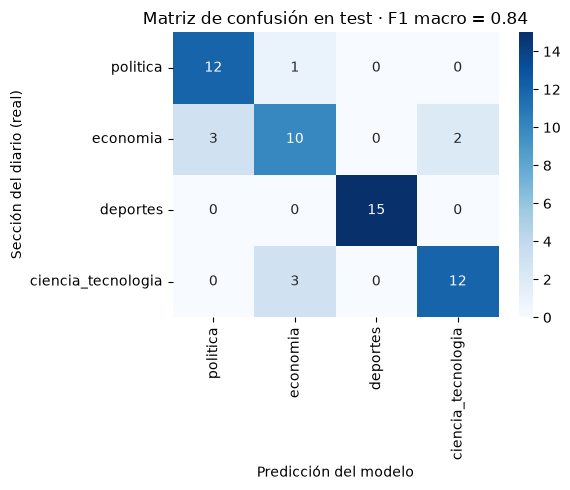

In [23]:
matriz = confusion_matrix(test["etiqueta"], test["prediccion_fine_tuned"], labels=CATEGORIAS)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIAS, yticklabels=CATEGORIAS)
plt.xlabel("Predicción del modelo")
plt.ylabel("Sección del diario (real)")
plt.title(f"Matriz de confusión en test · F1 macro = {f1_fine_tuned:.2f}")
plt.tight_layout()
plt.show()

In [24]:
# los errores, para entender de dónde vienen
errores = test[test["etiqueta"] != test["prediccion_fine_tuned"]]
errores[["titular", "etiqueta", "prediccion_fine_tuned", "etiqueta_llm"]]

,titular,etiqueta,prediccion_fine_tuned,etiqueta_llm
0,Viceministra de Minas: “Estamos estableciendo un plazo de 18 meses y no abrimos la pue...,politica,economia,economia
6,"Beatriz Boza, socia y líder de Familias Empresarias en EY: “La siguiente gran apuesta ...",economia,politica,economia
11,Pensionistas de la ONP recibirán su pensión en casa desde este jueves 15 de octubre,economia,politica,economia
12,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de l...,ciencia_tecnologia,economia,politica
19,"Daniel Velandia, economista jefe de Credicorp Capital: “Si las condiciones se dan desp...",economia,politica,economia
20,Indecopi se pronuncia sobre presunta filtración de datos en Interseguro,economia,ciencia_tecnologia,economia
41,Finlandia frena la construcción de dos centros de datos de Google por su impacto ambie...,ciencia_tecnologia,economia,ciencia_tecnologia
45,Ciberamenazas en América Latina: Perú registró mayor actividad de malware en el primer...,ciencia_tecnologia,economia,ciencia_tecnologia
54,"‘OxI Exprés’: obras para enfrentar El Niño aún no tienen convenios suscritos, ¿por qué?",economia,ciencia_tecnologia,economia


### Reflexión por categoría

- **Mejor: `deportes` (F1 = 1.00).** Tiene un vocabulario propio que casi no se cruza con las
  otras categorías: nombres de clubes (Alianza, Universitario), marcadores ("4-1"), "goles",
  "Liga 1", "| RESUMEN Y GOLES". El modelo no necesita entender la frase; le basta con esas pistas.
- **Peor: `economia` (F1 = 0.69).** Sus errores son noticias donde la economía se mezcla con el
  Estado o con la tecnología: una viceministra de Minas hablando de plazos (¿política o
  economía?), pensiones de la ONP, Indecopi y una filtración de datos, obras de prevención ante
  El Niño. Además, varios titulares de economía son **entrevistas que empiezan con el nombre y el
  cargo de una persona** ("Daniel Velandia, economista jefe de Credicorp...: '...'"), el mismo
  formato que usan las noticias políticas, y el modelo los confunde.
- `ciencia_tecnologia` (0.83) falla cuando la noticia trata de impacto económico o ambiental
  (centros de datos de Google en Finlandia, minería ilegal en Madre de Dios) y `politica` (0.86)
  "atrae" a las entrevistas a funcionarios.
- Parte del error viene de la etiqueta débil: el modelo aprendió de Gemini, y en 2 de los 9 errores
  Gemini tampoco coincidía con la sección del diario.

## 6. Comparativa y decisión

Para comparar en igualdad de condiciones, medimos los tres enfoques sobre **el mismo test
completo**. La latencia es el tiempo promedio por titular en esta laptop (CPU).

In [25]:
inicio = time.time()
test["prediccion_zero_shot"] = predecir_zero_shot(test["titular"])
segundos_zero_shot = time.time() - inicio

latencia_llm = segundos_api_llm / len(noticias)

comparativa = pd.DataFrame({
    "modelo": ["Zero-shot (BERT español XNLI)", f"LLM débil ({MODELO_LLM})", "DistilBERT fine-tuned"],
    "accuracy": [
        accuracy_score(test["etiqueta"], test["prediccion_zero_shot"]),
        accuracy_score(test["etiqueta"], test["etiqueta_llm"]),
        accuracy_fine_tuned,
    ],
    "f1_macro": [
        f1_score(test["etiqueta"], test["prediccion_zero_shot"], average="macro"),
        f1_score(test["etiqueta"], test["etiqueta_llm"], average="macro"),
        f1_fine_tuned,
    ],
    "segundos_por_titular": [
        segundos_zero_shot / len(test),
        latencia_llm,
        segundos_fine_tuned / len(test),
    ],
    "costo": ["Gratis, local (~440 MB)", "API externa: cuota y conexión", "Gratis, local (~540 MB)"],
})
comparativa.round(3)

,modelo,accuracy,f1_macro,segundos_por_titular,costo
0,Zero-shot (BERT español XNLI),0.621,0.606,0.792,"Gratis, local (~440 MB)"
1,LLM débil (gemini-3.5-flash-lite),0.948,0.946,0.081,API externa: cuota y conexión
2,DistilBERT fine-tuned,0.845,0.844,0.091,"Gratis, local (~540 MB)"


### ¿Cuál usaríamos en un entorno real?

| | Zero-shot | LLM (Gemini) | DistilBERT fine-tuned |
| :--- | :--- | :--- | :--- |
| F1 macro en test | 0.61 | **0.95** | 0.84 |
| Costo | gratis | cuota diaria (20 solicitudes/día en el plan gratuito) | gratis |
| Dependencia | local | internet + API externa | local |

- El **zero-shot** queda descartado: es el más lento (0.8 s por titular, porque evalúa las 4
  hipótesis por separado) y el menos preciso.
- El **LLM** es el más preciso, pero depende de una API externa: hoy mismo nos topamos con errores
  `503` por alta demanda y con el límite de 20 solicitudes diarias por modelo. Para un medio que
  publica cientos de notas al día eso no es confiable ni gratis.
- **Elegiríamos DistilBERT fine-tuned** para producción: corre en una laptop sin internet, tarda
  menos de 0.1 s por titular y su F1 (0.84) supera por mucho al piso zero-shot (0.59–0.61). El LLM
  sirve para lo que lo usamos aquí: **etiquetar datos de entrenamiento** una vez, y revisar los
  casos en que el modelo local tenga baja confianza.

In [26]:
# métricas que lee el dashboard (app.py)
metricas = {
    "f1_macro_test": round(f1_fine_tuned, 3),
    "accuracy_test": round(accuracy_fine_tuned, 3),
    "f1_zero_shot_40": round(f1_zero_shot_40, 3),
    "acuerdo_llm_humano": f"{acuerdos}/{len(auditoria)}",
    "porcentaje_acuerdo": round(porcentaje_acuerdo, 1),
    "noticias_test": len(test),
    "modelo_llm": MODELO_LLM,
}
with open("modelo/metricas.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas, archivo, ensure_ascii=False, indent=2)
metricas

{'f1_macro_test': 0.844,
 'accuracy_test': 0.845,
 'f1_zero_shot_40': 0.591,
 'acuerdo_llm_humano': '20/20',
 'porcentaje_acuerdo': 100.0,
 'noticias_test': 58,
 'modelo_llm': 'gemini-3.5-flash-lite'}

In [27]:
print("Para el comentario de entrega:")
print(f"Resultados Test: F1 Macro: {f1_fine_tuned:.3f} | Zero-shot: {f1_zero_shot_40:.3f} | Acuerdo LLM-Humano: {acuerdos}/{len(auditoria)}")

Para el comentario de entrega:
Resultados Test: F1 Macro: 0.844 | Zero-shot: 0.591 | Acuerdo LLM-Humano: 20/20


## Qué hicimos

| Paso | Código clave |
| :--- | :--- |
| Split 70/15/15 estratificado | `train_test_split(..., stratify=..., random_state=42)` dos veces |
| Línea base zero-shot (40 titulares) | `pipeline("zero-shot-classification", model="Recognai/...")` |
| Etiquetar con el LLM | `cliente.models.generate_content(..., response_schema=list[Clasificacion])` |
| Auditoría humana | `datos/auditoria_humana.csv` → `auditoria["acuerdo_humano"].sum()` |
| Fine-tuning | `Trainer(...)` con 3 épocas, lote 16, `metric_for_best_model="f1_macro"` |
| Evaluar en test | `f1_score(..., average="macro")`, `confusion_matrix` + `sns.heatmap` |
| Comparar | tabla zero-shot vs LLM vs fine-tuned |
| Guardar | `entrenador.save_model("modelo")`, `modelo/metricas.json` |